# Лабораторна робота №2
## PCA, t-SNE, кластеризація та класифікація текстових даних

### Мета роботи
Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.

### Дані
Для частин 1–2 використовується датасет **Classification of Malwares (CLaMP)** з лабораторної роботи №1.

Для частини 3 використовується **Phishing Email Dataset**. Для швидкого та відтворюваного виконання використано збалансовану вибірку з **10 000 листів**: 5 000 legitimate та 5 000 phishing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from wordcloud import WordCloud

RANDOM_STATE = 42

# 1. Зниження розмірності та візуалізація даних

Завантажимо CLaMP та повторимо preprocessing із Lab 1: видалимо повністю порожні колонки `e_res`, `e_res2` і дублікати.

In [2]:
CLAMP_LOCAL = Path("ClaMP_Raw-5184.csv")
CLAMP_URL = "https://raw.githubusercontent.com/maksymenkokyrylofb61mp/IAD-Lab1-CLaMP/main/ClaMP_Raw-5184.csv"

clamp_source = CLAMP_LOCAL if CLAMP_LOCAL.exists() else CLAMP_URL
df = pd.read_csv(clamp_source)

print("Початковий розмір:", df.shape)
df = df.drop(columns=["e_res", "e_res2"])
df = df.drop_duplicates().reset_index(drop=True)

print("Розмір після очищення:", df.shape)
print("Пропущені значення:", df.isnull().sum().sum())
print("Дублікати:", df.duplicated().sum())
print("\nРозподіл класів:")
print(df["class"].value_counts())

Початковий розмір: (5184, 56)
Розмір після очищення: (4560, 54)
Пропущені значення: 0
Дублікати: 0

Розподіл класів:
class
0    2488
1    2072
Name: count, dtype: int64


In [3]:
X = df.drop(columns="class")
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (3648, 53)
X_test: (912, 53)


## 1.1. Класифікація до PCA

Для порівняння використаємо **Random Forest**, оскільки в Lab 1 ця модель показала найкращий результат.

In [4]:
rf_before = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

start = time.perf_counter()
rf_before.fit(X_train, y_train)
train_time_before = time.perf_counter() - start

pred_before = rf_before.predict(X_test)
accuracy_before = accuracy_score(y_test, pred_before)

print(f"Кількість ознак до PCA: {X_train.shape[1]}")
print(f"Accuracy до PCA: {accuracy_before:.4f}")
print(f"Час навчання до PCA: {train_time_before:.4f} с")

Кількість ознак до PCA: 53
Accuracy до PCA: 0.9890
Час навчання до PCA: 0.3084 с


## 1.2. PCA

Перед PCA виконаємо стандартизацію. `StandardScaler` та `PCA` навчаються лише на training-вибірці. Залишимо мінімальну кількість компонент, що пояснюють не менше **95% дисперсії**.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Кількість ознак до PCA:", X_train.shape[1])
print("Кількість компонент після PCA:", pca.n_components_)
print(f"Пояснена дисперсія: {pca.explained_variance_ratio_.sum():.4f}")

Кількість ознак до PCA: 53
Кількість компонент після PCA: 30
Пояснена дисперсія: 0.9542


In [6]:
rf_after = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

start = time.perf_counter()
rf_after.fit(X_train_pca, y_train)
train_time_after = time.perf_counter() - start

pred_after = rf_after.predict(X_test_pca)
accuracy_after = accuracy_score(y_test, pred_after)

pca_comparison = pd.DataFrame({
    "Варіант": ["До PCA", "Після PCA"],
    "Кількість ознак": [X_train.shape[1], pca.n_components_],
    "Accuracy": [accuracy_before, accuracy_after],
    "Час навчання, с": [train_time_before, train_time_after]
})
pca_comparison

,Варіант,Кількість ознак,Accuracy,"Час навчання, с"
0,До PCA,53,0.989035,0.308369
1,Після PCA,30,0.972588,0.608515


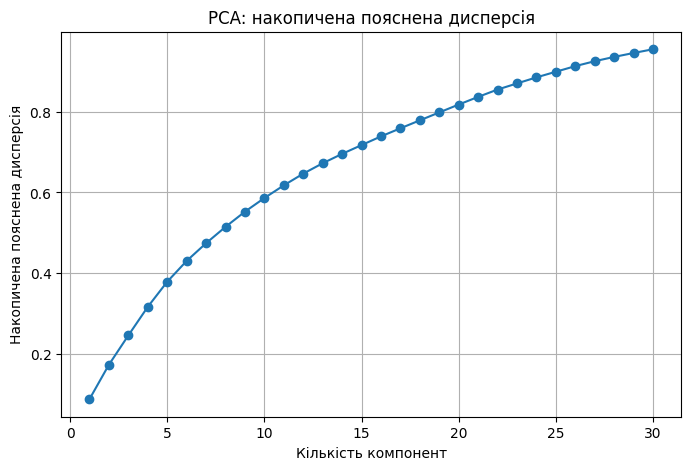

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, pca.n_components_ + 1),
         np.cumsum(pca.explained_variance_ratio_),
         marker="o")
plt.xlabel("Кількість компонент")
plt.ylabel("Накопичена пояснена дисперсія")
plt.title("PCA: накопичена пояснена дисперсія")
plt.grid()
plt.show()

### Висновок щодо PCA
PCA зменшує кількість ознак, зберігаючи близько 95% дисперсії. За таблицею вище можна порівняти точність та час навчання Random Forest до і після PCA. Незначне падіння accuracy є можливим компромісом за компактніше представлення даних.

## 1.3. t-SNE до 2D

t-SNE є обчислювально дорогим алгоритмом, тому для 2D-візуалізації використовується **стратифікована підвибірка 1500 об'єктів** із того самого CLaMP, зі збереженням співвідношення класів. Перед t-SNE дані стискаються PCA до 20 компонент для прискорення та зменшення шуму.


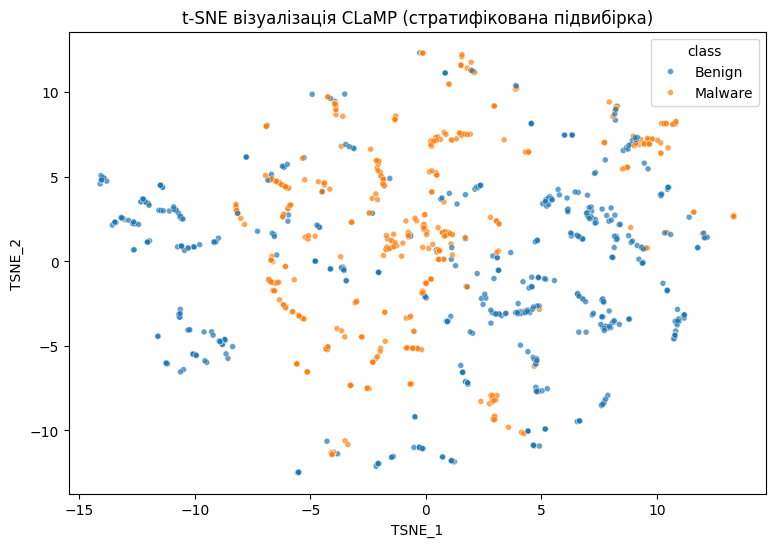

In [8]:
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)

# Для t-SNE беремо стратифіковану підвибірку 1500 об'єктів,
# оскільки t-SNE є обчислювально дорогим і використовується тут для візуалізації.
tsne_idx, _ = train_test_split(
    np.arange(len(y)),
    train_size=1500,
    random_state=RANDOM_STATE,
    stratify=y
)

X_tsne_sample = X_scaled_full[tsne_idx]
y_tsne_sample = y.iloc[tsne_idx].reset_index(drop=True)

# Попереднє PCA прискорює t-SNE та прибирає частину шуму
pca_for_tsne = PCA(n_components=20)
X_tsne_input = pca_for_tsne.fit_transform(X_tsne_sample)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=300,
    random_state=RANDOM_STATE
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = pd.DataFrame({
    "TSNE_1": X_tsne[:, 0],
    "TSNE_2": X_tsne[:, 1],
    "class": y_tsne_sample.map({0: "Benign", 1: "Malware"})
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tsne_df,
    x="TSNE_1",
    y="TSNE_2",
    hue="class",
    s=18,
    alpha=0.7
)
plt.title("t-SNE візуалізація CLaMP (стратифікована підвибірка)")
plt.show()


### Висновок щодо t-SNE
t-SNE відображає локальну структуру даних. Часткове перекриття Benign і Malware означає, що класи не мають ідеального двовимірного розділення, хоча окремі області можуть бути більш характерними для певного класу.

# 2. Кластерний аналіз

Під час кластеризації `class` не використовується. K-Means отримує тільки числові ознаки `X`. Перевіримо `k` від 2 до 10 за Elbow Method та Silhouette Score.

In [9]:
k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled_full)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(
            X_scaled_full, labels,
            sample_size=3000,
            random_state=RANDOM_STATE
        )
    )

cluster_metrics = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})
cluster_metrics

,k,Inertia,Silhouette Score
0,2,218563.510218,0.853194
1,3,196476.869830,0.851480
2,4,178861.114325,0.852468
3,5,168951.195211,0.853942
4,6,158146.779278,0.146384
5,7,149661.167965,0.183294
6,8,137250.407501,0.217680
7,9,130437.235025,0.188059
8,10,120874.059879,0.266358


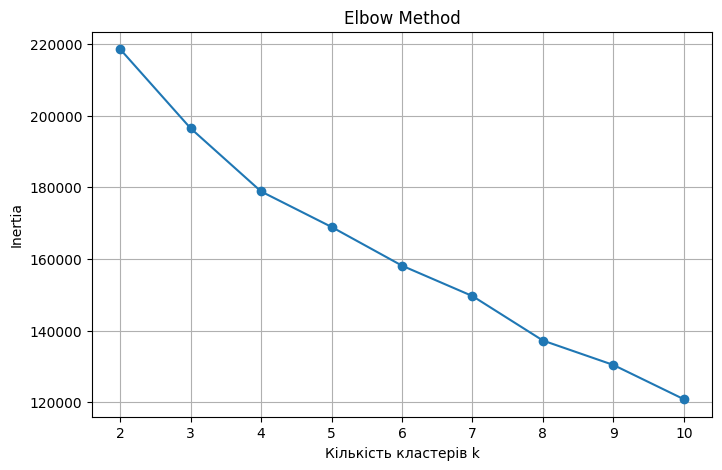

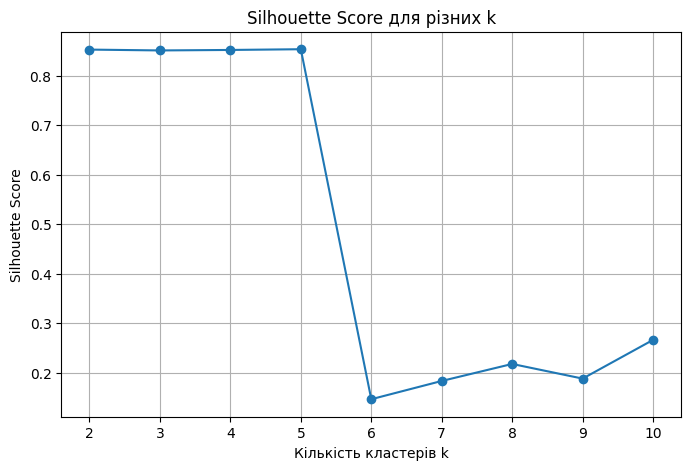

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(cluster_metrics["k"], cluster_metrics["Inertia"], marker="o")
plt.xlabel("Кількість кластерів k")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(cluster_metrics["k"], cluster_metrics["Silhouette Score"], marker="o")
plt.xlabel("Кількість кластерів k")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score для різних k")
plt.grid()
plt.show()

In [11]:
best_k = int(cluster_metrics.loc[
    cluster_metrics["Silhouette Score"].idxmax(), "k"
])
print("Найкраще k за Silhouette Score:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled_full)

Найкраще k за Silhouette Score: 5


## 2.1. Візуалізація кластерів у 2D

Для візуалізації кластерів використаємо PCA до двох компонент. Колір означає номер знайденого кластера, а не реальний клас.

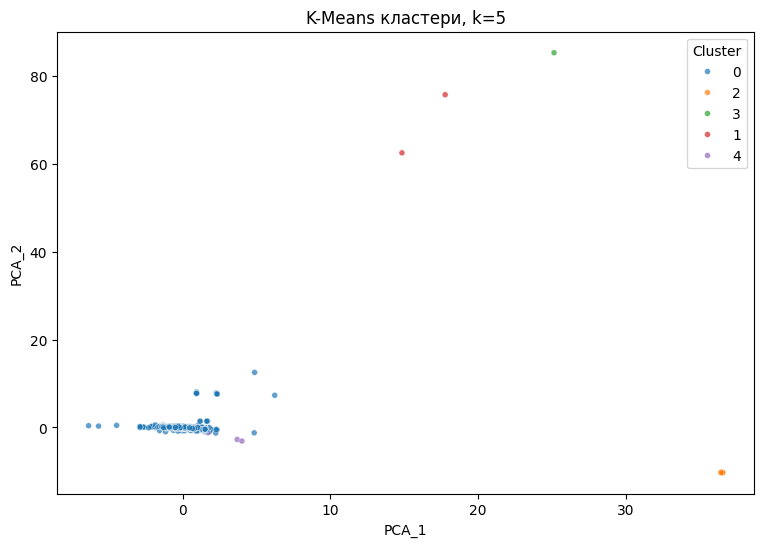

In [12]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled_full)

cluster_plot = pd.DataFrame({
    "PCA_1": X_pca_2d[:, 0],
    "PCA_2": X_pca_2d[:, 1],
    "Cluster": clusters.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=cluster_plot, x="PCA_1", y="PCA_2",
                hue="Cluster", s=18, alpha=0.7)
plt.title(f"K-Means кластери, k={best_k}")
plt.show()

## 2.2. Порівняння кластерів зі справжніми класами

Оскільки номери кластерів довільні, не використовуємо звичайну accuracy. Замість цього аналізуємо таблицю перетину та ARI/NMI.

In [13]:
comparison = pd.crosstab(
    y, clusters,
    rownames=["Справжній class"],
    colnames=["Cluster"]
)
display(comparison)

ari = adjusted_rand_score(y, clusters)
nmi = normalized_mutual_info_score(y, clusters)

print(f"Adjusted Rand Index: {ari:.4f}")
print(f"Normalized Mutual Information: {nmi:.4f}")

Cluster,0,1,2,3,4
Справжній class,,,,,
0,2477,0,11,0,0
1,2066,2,0,1,3


Adjusted Rand Index: -0.0003
Normalized Mutual Information: 0.0070


### Висновок щодо кластеризації
Навіть високий Silhouette Score не означає відповідність кластерів класам Benign/Malware. Таблиця перетину та ARI/NMI показують, наскільки знайдена геометрична структура узгоджується з реальними мітками. K-Means шукає групи без знання target, тому кластери та класи не зобов'язані збігатися.

# 3. Обробка та класифікація текстових даних

Використаємо збалансовану вибірку Phishing Email Dataset:
- `0` — Legitimate;
- `1` — Phishing.

Виконаємо очищення тексту, WordCloud, TF-IDF та класифікацію за допомогою Logistic Regression.

In [14]:
PHISH_LOCAL = Path("phishing_email_sample_10000.csv")
PHISH_URL = "https://raw.githubusercontent.com/maksymenkokyrylofb61mp/IAD-Lab1-CLaMP/main/phishing_email_sample_10000.csv"

phish_source = PHISH_LOCAL if PHISH_LOCAL.exists() else PHISH_URL
text_df = pd.read_csv(phish_source)

print("Розмір:", text_df.shape)
print("\nРозподіл класів:")
print(text_df["label"].value_counts())
print("\nПропущені значення:")
print(text_df.isnull().sum())
display(text_df.head())

Розмір: (10000, 2)

Розподіл класів:
label
1    5000
0    5000
Name: count, dtype: int64

Пропущені значення:
text_combined    0
label            0
dtype: int64


,text_combined,label
0,daily top 10 marshes_1996movadogroupcom daily ...,1
1,new nomination tejas forwarded ami chokshi cor...,0
2,gamasutra rssfeedsspamassassintaintorg url htt...,0
3,mino xjvoqdhgmailcom hello please tell buy scr...,0
4,california capacity report week 10 22 10 26 tr...,0


## 3.1. Передобробка тексту

Текст переводимо у нижній регістр, видаляємо URL, цифри, пунктуацію та англійські stop-words.

In [15]:
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in stop_words and len(w) > 2]
    return " ".join(words)

text_df["clean_text"] = text_df["text_combined"].apply(clean_text)
text_df = text_df[text_df["clean_text"].str.len() > 0].reset_index(drop=True)

print("Розмір після очищення:", text_df.shape)
display(text_df[["text_combined", "clean_text", "label"]].head())

Розмір після очищення: (9999, 3)


,text_combined,clean_text,label
0,daily top 10 marshes_1996movadogroupcom daily ...,daily marshes movadogroupcom daily cnncom vide...,1
1,new nomination tejas forwarded ami chokshi cor...,new nomination tejas forwarded ami chokshi cor...,0
2,gamasutra rssfeedsspamassassintaintorg url htt...,gamasutra rssfeedsspamassassintaintorg url dat...,0
3,mino xjvoqdhgmailcom hello please tell buy scr...,mino xjvoqdhgmailcom hello tell buy script all...,0
4,california capacity report week 10 22 10 26 tr...,california capacity report week transwestern a...,0


## 3.2. WordCloud

Побудуємо окремі хмари слів для legitimate і phishing. Для швидкості WordCloud використовує випадкову підвибірку текстів кожного класу.

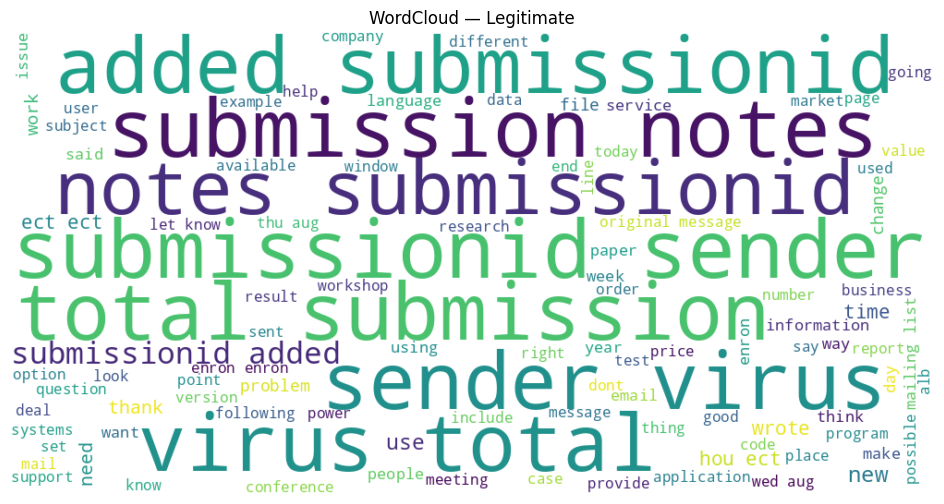

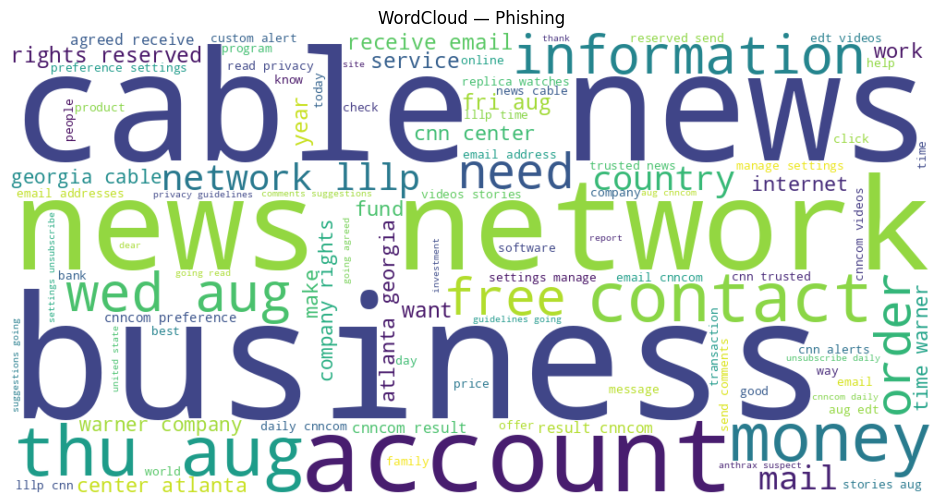

In [16]:
label_names = {0: "Legitimate", 1: "Phishing"}

for label, label_name in label_names.items():
    texts = text_df.loc[text_df["label"] == label, "clean_text"]
    texts = texts.sample(n=min(1000, len(texts)), random_state=RANDOM_STATE)
    class_text = " ".join(texts)
    class_text = class_text[:1_000_000]

    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100
    ).generate(class_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud — {label_name}")
    plt.show()

### Коментар до WordCloud
WordCloud показує найчастіші слова в кожному класі. Частота слова сама по собі не визначає його корисність для класифікації, тому далі використовується TF-IDF.

## 3.3. TF-IDF та класифікація

`TfidfVectorizer` навчається тільки на training-вибірці. Для класифікації використовується Logistic Regression.

In [17]:
X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    text_df["clean_text"],
    text_df["label"],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=text_df["label"]
)

tfidf = TfidfVectorizer(
    max_features=6000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_test_tfidf = tfidf.transform(X_text_test)

print("TF-IDF train shape:", X_text_train_tfidf.shape)
print("TF-IDF test shape:", X_text_test_tfidf.shape)

TF-IDF train shape: (7999, 6000)
TF-IDF test shape: (2000, 6000)


In [18]:
text_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

start = time.perf_counter()
text_model.fit(X_text_train_tfidf, y_text_train)
text_train_time = time.perf_counter() - start

text_pred = text_model.predict(X_text_test_tfidf)
text_accuracy = accuracy_score(y_text_test, text_pred)

print(f"Accuracy: {text_accuracy:.4f}")
print(f"Час навчання: {text_train_time:.4f} с")
print("\nClassification report:")
print(classification_report(
    y_text_test, text_pred,
    target_names=["Legitimate", "Phishing"]
))

Accuracy: 0.9680
Час навчання: 0.0544 с

Classification report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.96      0.97      1000
    Phishing       0.96      0.97      0.97      1000

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



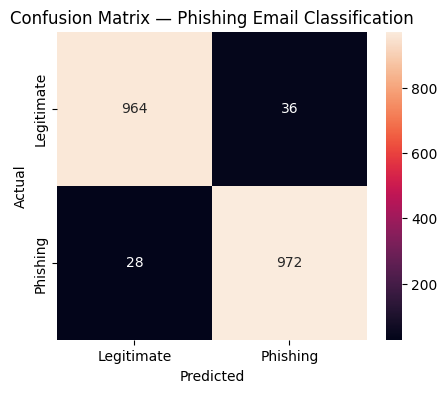

In [19]:
cm = confusion_matrix(y_text_test, text_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Phishing Email Classification")
plt.show()

# Загальний висновок

1. **PCA** дозволяє зменшити кількість ознак CLaMP, зберігаючи близько 95% дисперсії. Порівняння Random Forest до/після PCA демонструє компроміс між компактністю представлення, точністю та часом навчання.
2. **t-SNE** дає двовимірну візуалізацію локальної структури CLaMP і показує, наскільки області Benign/Malware перекриваються.
3. **K-Means** працює без target і не зобов'язаний відтворювати класи Benign/Malware. Відповідність оцінюється через crosstab, ARI та NMI.
4. Для phishing email виконано очищення тексту, WordCloud, TF-IDF та Logistic Regression. Отримані метрики дозволяють оцінити якість розпізнавання legitimate та phishing листів.